In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import accuracy_score

In [2]:
dataset = pd.read_csv('Social_Network_Ads.csv')
X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, -1].values

In [3]:
from sklearn.model_selection import train_test_split, cross_val_score
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 0)

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel = 'rbf', random_state = 0))
])

In [5]:
accuracies = cross_val_score(estimator = pipeline, X = X_train, y= y_train, cv = 10)
print("Accuracy:{:.2f}%".format(accuracies.mean()*100))
print("Standard Deviation:{:.2f}%".format(accuracies.std()*100))

Accuracy:90.33%
Standard Deviation:6.57%


In [6]:
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
print(cm)
final_accuracy = accuracy_score(y_test, y_pred)
print("Final Test Accuracy: {:.2f} %".format(final_accuracy * 100))

[[64  4]
 [ 3 29]]
Final Test Accuracy: 93.00 %


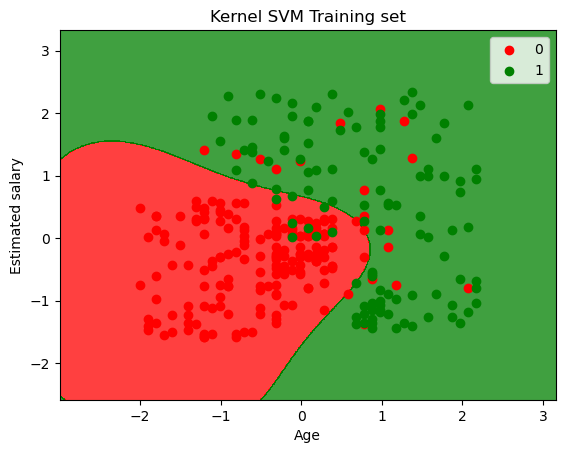

In [7]:
from matplotlib.colors import ListedColormap

fitted_scaler = pipeline.named_steps['scaler']
fitted_svm = pipeline.named_steps['svm']

X_set = fitted_scaler.transform(X_train)
y_set = y_train

X1, X2 = np.meshgrid(
    np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.01),
    np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.01)
)

plt.contourf(X1, X2, fitted_svm.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green')))

plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())

for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                color = ListedColormap(('red', 'green'))(i), label = j)

plt.title('Kernel SVM Training set')
plt.xlabel('Age')
plt.ylabel('Estimated salary')
plt.legend()
plt.show()

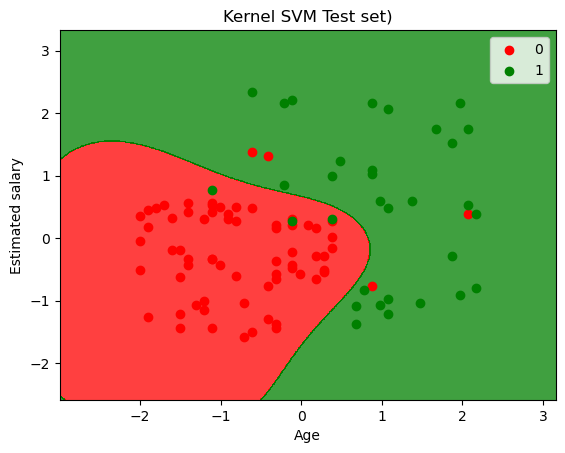

In [8]:
from matplotlib.colors import ListedColormap

fitted_scaler = pipeline.named_steps['scaler']
fitted_svm = pipeline.named_steps['svm']

X_set = fitted_scaler.transform(X_test)
y_set = y_test

X1, X2 = np.meshgrid(
    np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.01),
    np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.01)
)

plt.contourf(X1, X2, fitted_svm.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green')))

plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())

for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                color = ListedColormap(('red', 'green'))(i), label = j)

plt.title('Kernel SVM Test set)')
plt.xlabel('Age')
plt.ylabel('Estimated salary')
plt.legend()
plt.show()